# Complex rules opposite to their simpler rules
Complex rules that passed p, then FDR, then point the other way (attract vs avoid) from all their significant simpler rules in the same field.

In [11]:
import os
import sys

import pandas as pd

sys.path[:0] = [os.path.abspath("scripts"), os.path.abspath(".."), os.path.abspath("../differential_rules/scripts")]
import classification_comparison as cc
import complex_investigation as ci
import data_helper as dh
import significance_histograms_vis as sh

In [12]:
MAX_FDR = 0.05
P_CUT = 0.05
PREFIX = "opposite"
LABELS = ["opposite to all simpler rules"] + sh.group_labels(P_CUT, MAX_FDR)
COLORS = [sh.OPPOSITE] + sh.COLORS
P_LINE = (P_CUT, f"p = {P_CUT}")
N_EXAMPLES = 5
KINDS = {"attracts": "attracts (lift > 1)", "avoids": "avoids (lift < 1)"}
DIRECTIONS = {"complex-antecedents": "many to one", "complex-consequents": "one to many"}

In [13]:
rules = dh._read_rules(dh.RESULT_CSV_PATH, rule_max_items=4)
complex_rules = rules[rules.Rule_Type.ne("pairwise")]
comparisons = pd.read_csv(os.path.join(dh.RESULT_CSV_PATH, "results_CN_comparisons.csv"),
                          usecols=["FOV", "rule_idx", "simpler_idx", "simpler_rule", "Kind"])
cells, metadata, _ = dh.load_spatial_data()

Read results_CN_pairwise.csv + results_CN_complex.csv
Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71


In [14]:
shape = sh.shape_and_size(complex_rules)
opposite = ci.opposite_to_simpler(rules, comparisons)[complex_rules.index]
groups = sh.with_opposite(sh.significance(complex_rules, P_CUT, MAX_FDR), opposite)
opposite_rules = complex_rules[opposite]
size = (opposite_rules.len_ant + opposite_rules.len_con).astype(str) + " items"
passed = opposite_rules[groups[opposite].eq(0)]
picks, prepared = ci.opposite_examples(passed, rules, comparisons, metadata, N_EXAMPLES)

## 1. How many pass each step

In [15]:
stages = pd.DataFrame({"all": True,
                       f"p ≤ {P_CUT}": groups.between(0, 2),
                       f"FDR ≤ {MAX_FDR}": groups.between(0, 1),
                       "opposite": groups.eq(0)})
per_fov = stages.groupby([complex_rules.FOV, shape], observed=True).sum()

display(stages.groupby(shape, observed=True).sum())
display(per_fov.groupby(level=1, observed=True).describe().drop(columns=["count", "std"], level=1).T.round(1))

,all,p ≤ 0.05,FDR ≤ 0.05,opposite
Multiple antecedents · 3 items,139872,76631,42188,314
Multiple antecedents · 4 items,479955,244317,82259,349
Multiple consequents · 3 items,60114,31716,16830,10
Multiple consequents · 4 items,101891,44157,13655,4


Multiple antecedents · 3 items  \
all        mean                           485.7   
           min                             58.0   
           25%                            331.5   
           50%                            466.0   
           75%                            633.2   
           max                           1016.0   
p ≤ 0.05   mean                           266.1   
           min                             42.0   
           25%                            184.8   
           50%                            262.0   
           75%                            344.5   
           max                            682.0   
FDR ≤ 0.05 mean                           146.5   
           min                              0.0   
           25%                             81.0   
           50%                            136.0   
           75%                            196.0   
           max                            526.0   
opposite   mean                             1.1   
           min                              0.0   
           25%                              0.0   
           50%                              1.0   
           75%                              2.0   
           max                              7.0   

                 Multiple antecedents · 4 items  \
all        mean                          1666.5   
           min                             85.0   
           25%                           1060.8   
           50%                           1587.0   
           75%                           2176.2   
           max                           4096.0   
p ≤ 0.05   mean                           848.3   
           min                             73.0   
           25%                            530.2   
           50%                            790.0   
           75%                           1069.8   
           max                           2908.0   
FDR ≤ 0.05 mean                           285.6   
           min                              0.0   
           25%                              0.0   
           50%                            227.0   
           75%                            489.0   
           max                           1728.0   
opposite   mean                             1.2   
           min                              0.0   
           25%                              0.0   
           50%                              0.0   
           75%                              1.2   
           max                             18.0   

                 Multiple consequents · 3 items  \
all        mean                           208.7   
           min                             33.0   
           25%                            149.0   
           50%                            202.0   
           75%                            268.2   
           max                            425.0   
p ≤ 0.05   mean                           110.1   
           min                             18.0   
           25%                             69.0   
           50%                            109.5   
           75%                            141.2   
           max                            310.0   
FDR ≤ 0.05 mean                            58.4   
           min                              0.0   
           25%                             32.0   
           50%                             51.5   
           75%                             81.0   
           max                            196.0   
opposite   mean                             0.0   
           min                              0.0   
           25%                              0.0   
           50%                              0.0   
           75%                              0.0   
           max                              3.0   

                 Multiple consequents · 4 items  
all        mean                           353.8  
           min                             25.0  
           25%                         

## 2. Rule p-values

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_p_values_Multiple_antecedents_3_items.pdf


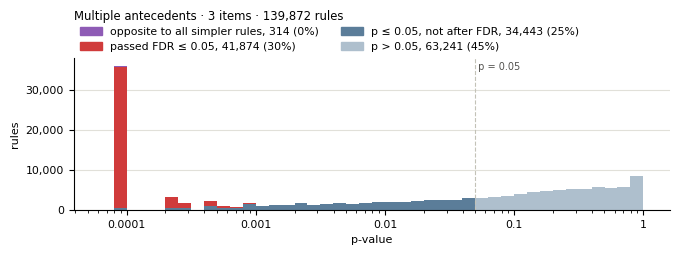

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_p_values_Multiple_antecedents_4_items.pdf


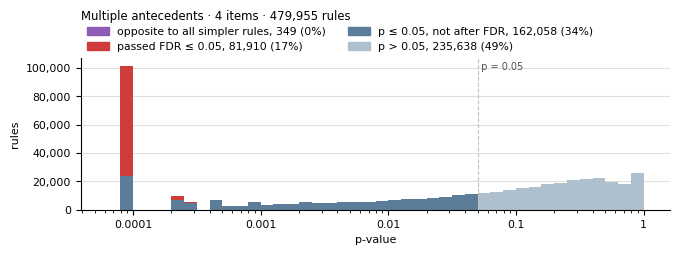

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_p_values_Multiple_consequents_3_items.pdf


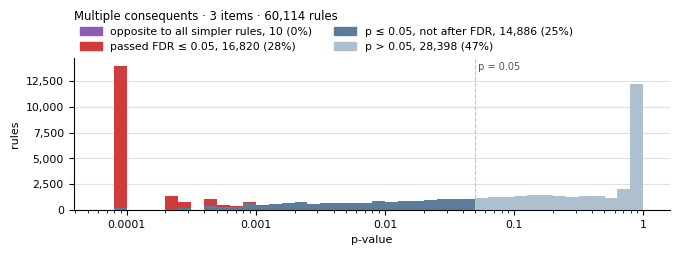

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_p_values_Multiple_consequents_4_items.pdf


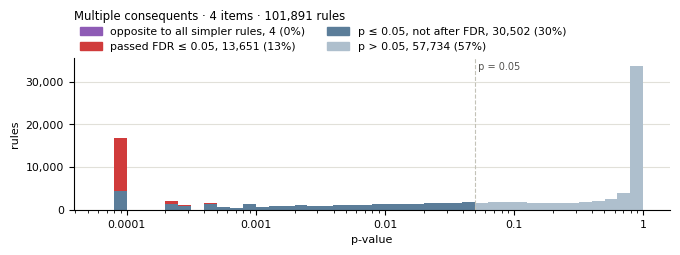

In [16]:
sh.histograms(sh.counts(complex_rules.P_Value, shape, groups, sh.P_BINS),
              sh.P_BINS, LABELS, "p-value", "rules", f"{PREFIX}_p_values", P_LINE, COLORS)

## 3. Opposite rules
One pie per number of items. The own test covers all opposite rules; the other two show all of them, then only those that passed FDR.

### Their own test

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_tests.pdf


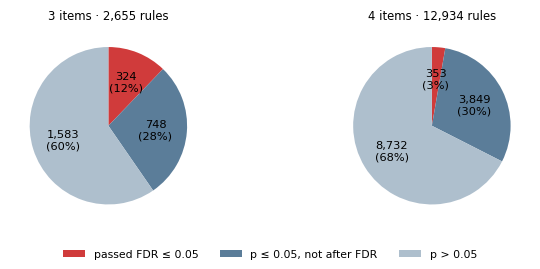

In [17]:
tests = pd.crosstab(size, sh.significance(opposite_rules, P_CUT, MAX_FDR)).reindex(columns=range(3), fill_value=0)
sh.pies(tests.set_axis(sh.group_labels(P_CUT, MAX_FDR), axis=1), sh.COLORS, f"{PREFIX}_tests")

### Attract or avoid

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_kinds_all.pdf


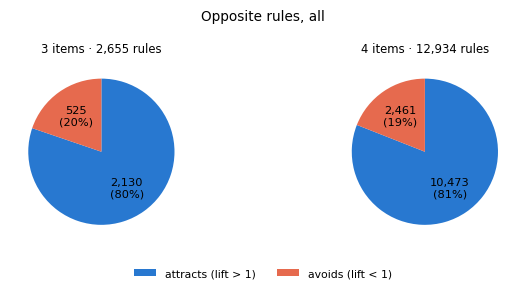

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_kinds_passed_FDR.pdf


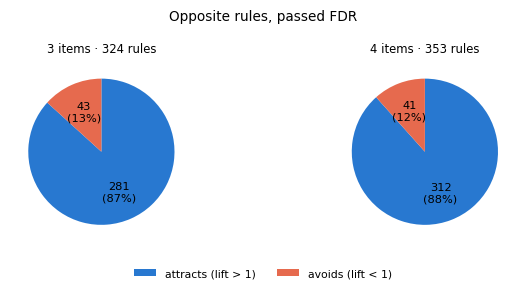

In [18]:
for name, here in {"all": opposite_rules, "passed FDR": passed}.items():
    sh.pies(pd.crosstab(size[here.index], here.Kind.map(KINDS)), [sh.vh.ATTRACTION, sh.vh.AVOIDANCE],
            f"{PREFIX}_kinds_{name.replace(' ', '_')}", f"Opposite rules, {name}")

### Many to one or one to many

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_directions_all.pdf


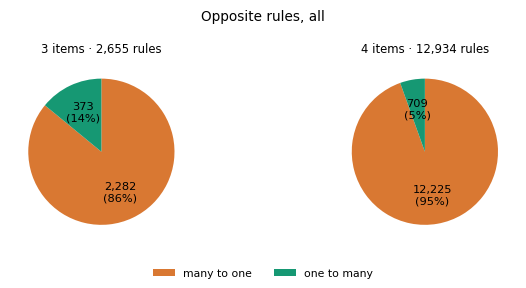

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_directions_passed_FDR.pdf


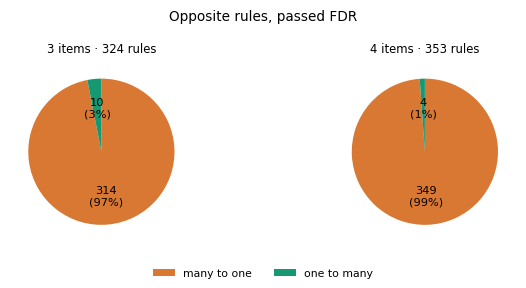

In [19]:
for name, here in {"all": opposite_rules, "passed FDR": passed}.items():
    sh.pies(pd.crosstab(size[here.index], here.Rule_Type.map(DIRECTIONS)), sh.vh.SHARE_COLORS,
            f"{PREFIX}_directions_{name.replace(' ', '_')}", f"Opposite rules, {name}")

## 4. Examples
The N_EXAMPLES lowest-FDR opposite rules that passed FDR, for each number of items and shape, next to one of their significant simpler rules in the same field.

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_1_fovs.pdf


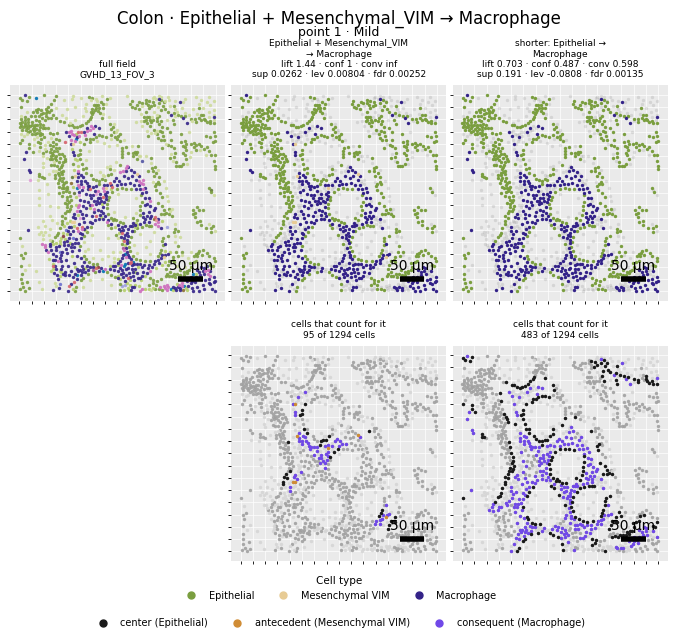

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_2_fovs.pdf


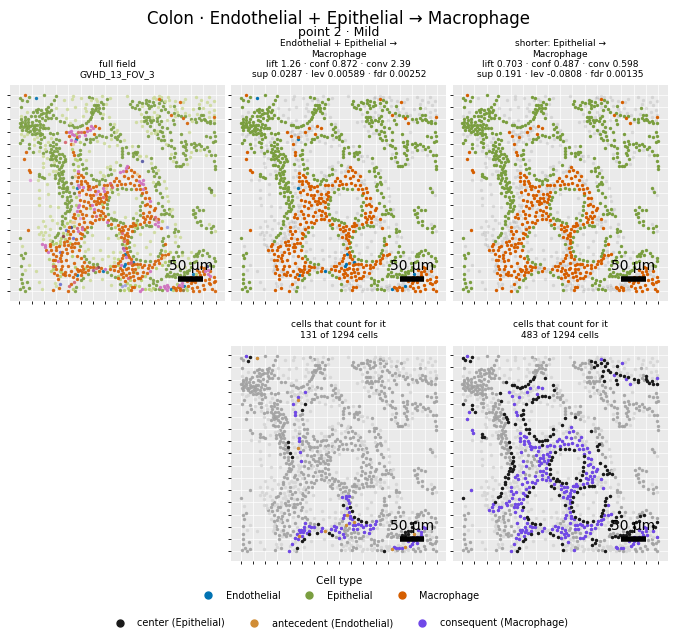

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_3_fovs.pdf


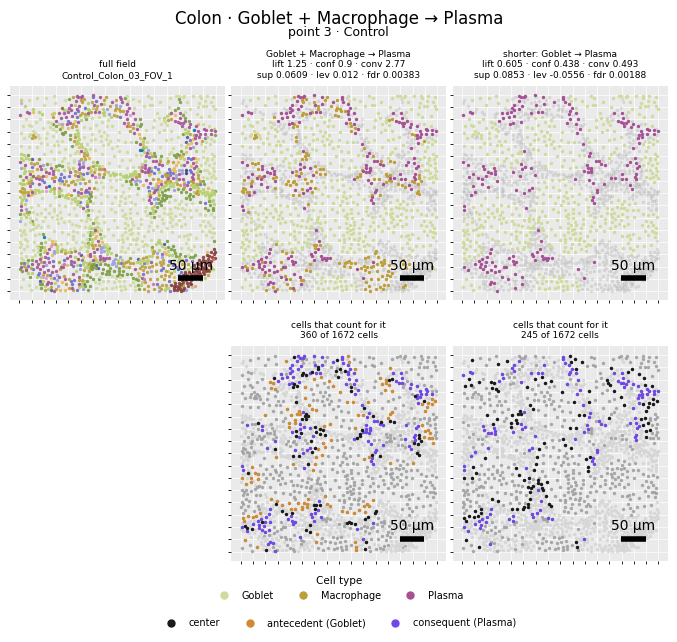

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_4_fovs.pdf


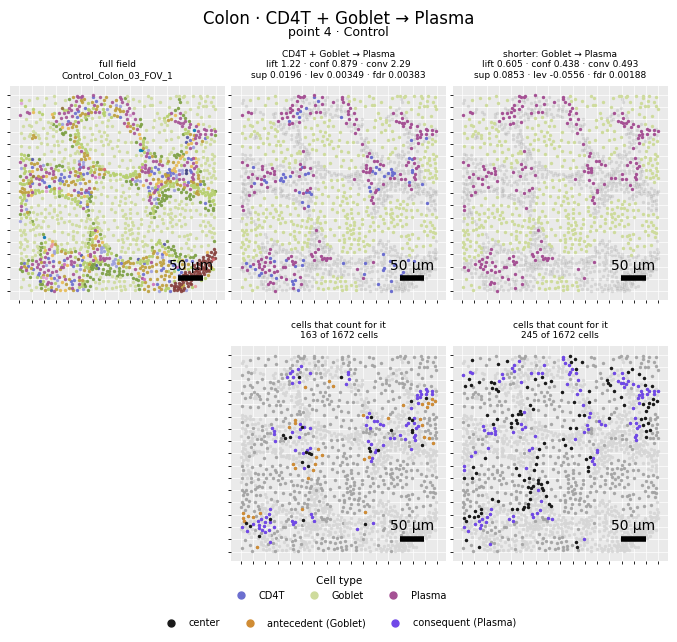

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_5_fovs.pdf


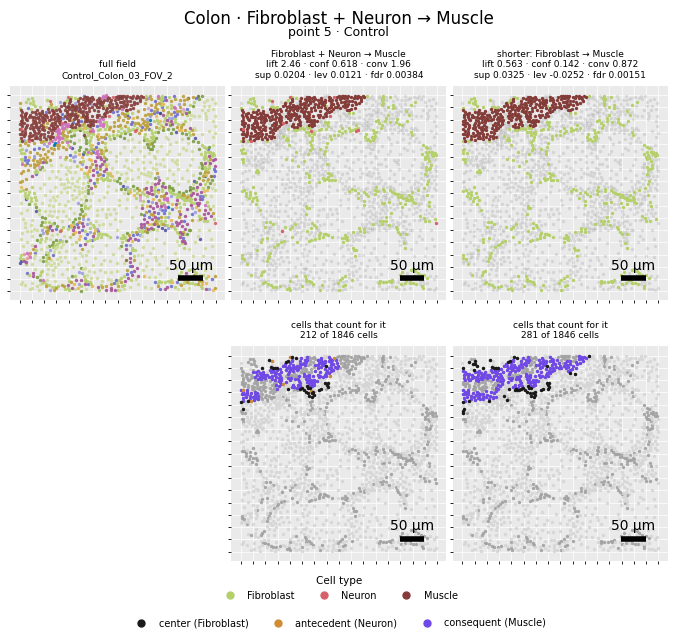

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-consequents_avoids_6_fovs.pdf


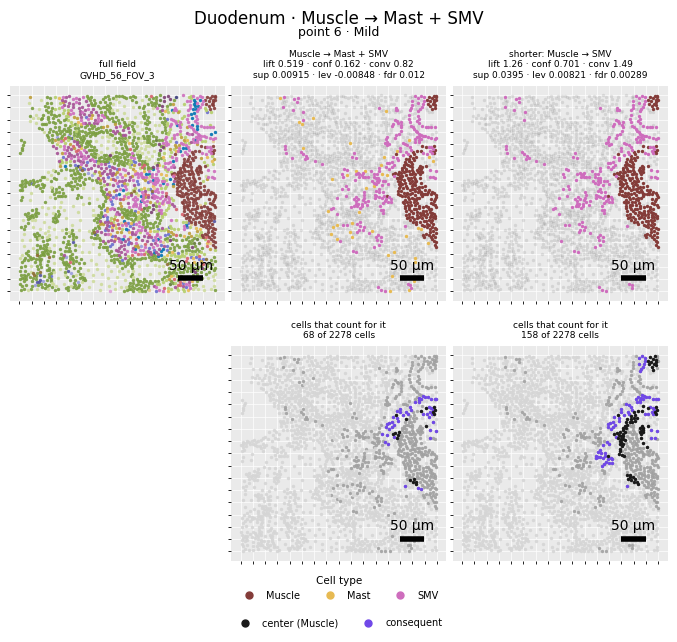

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-consequents_avoids_7_fovs.pdf


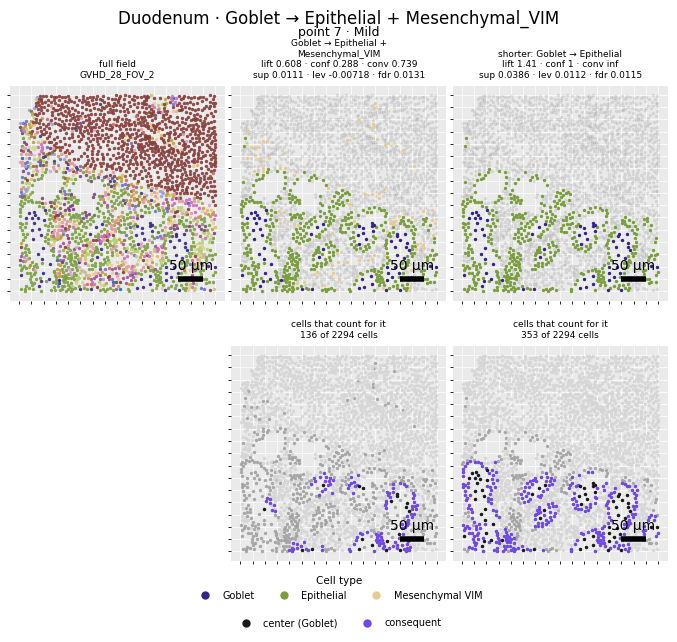

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-consequents_avoids_8_fovs.pdf


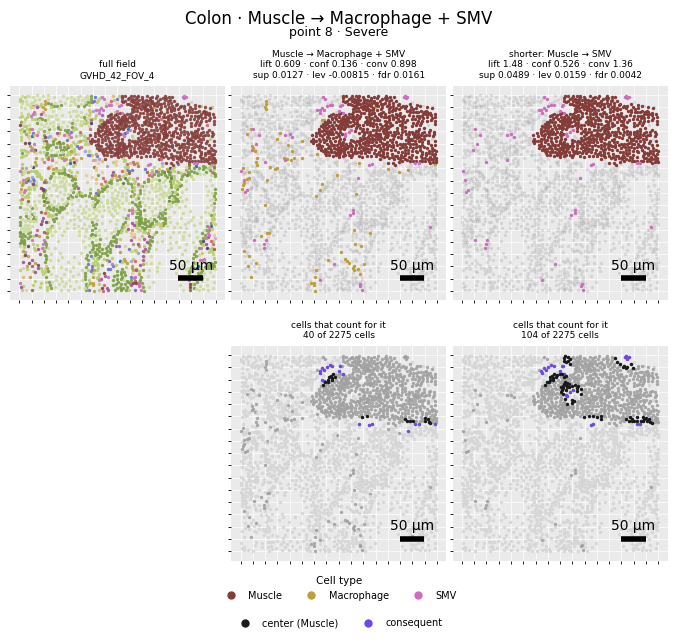

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-consequents_avoids_9_fovs.pdf


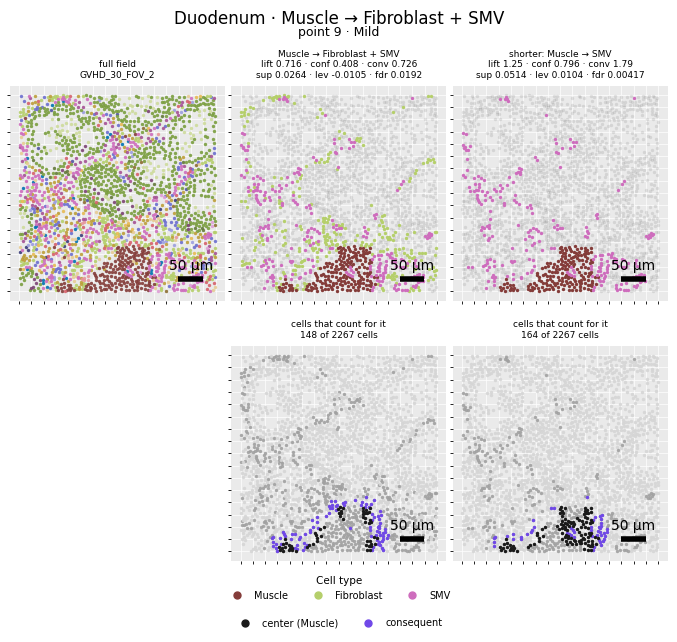

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_10_fovs.pdf


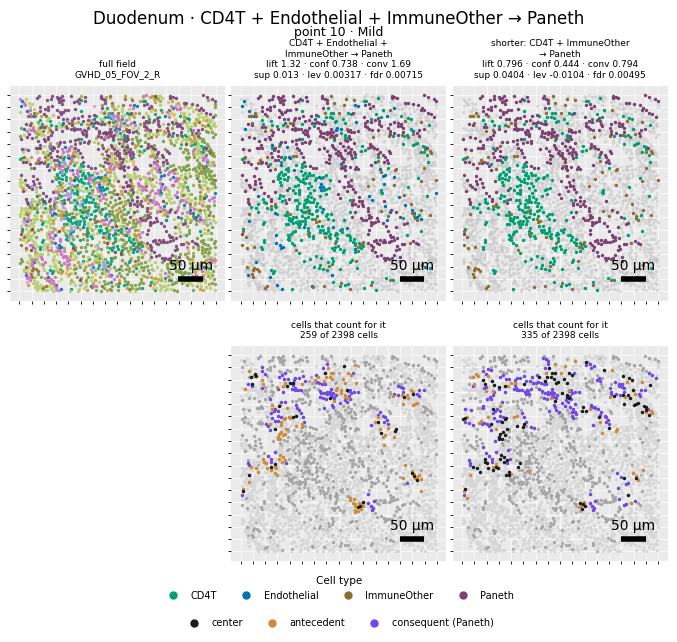

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_11_fovs.pdf


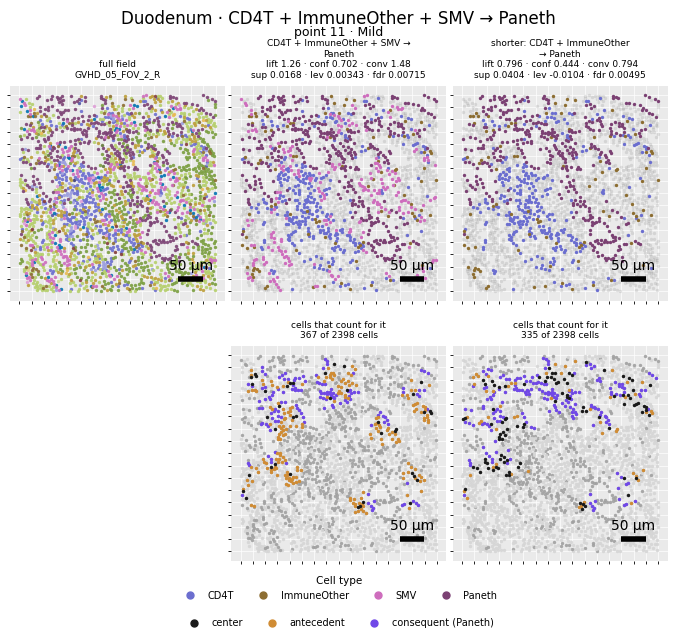

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_12_fovs.pdf


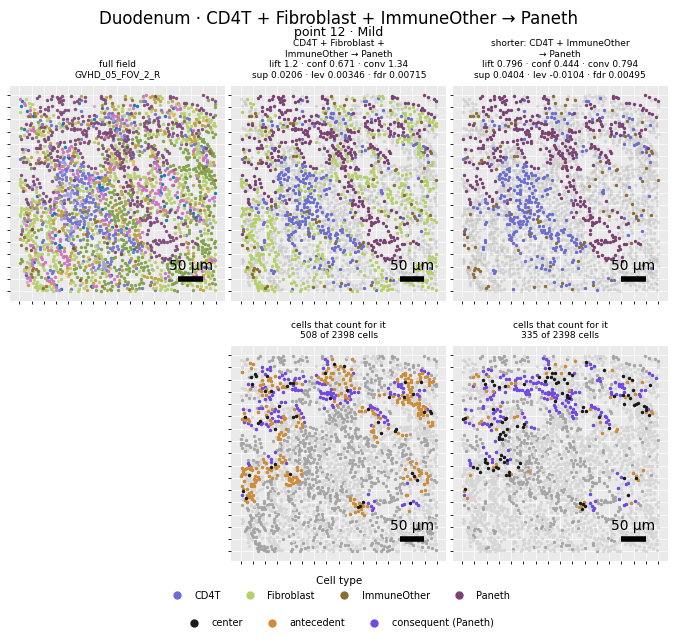

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_13_fovs.pdf


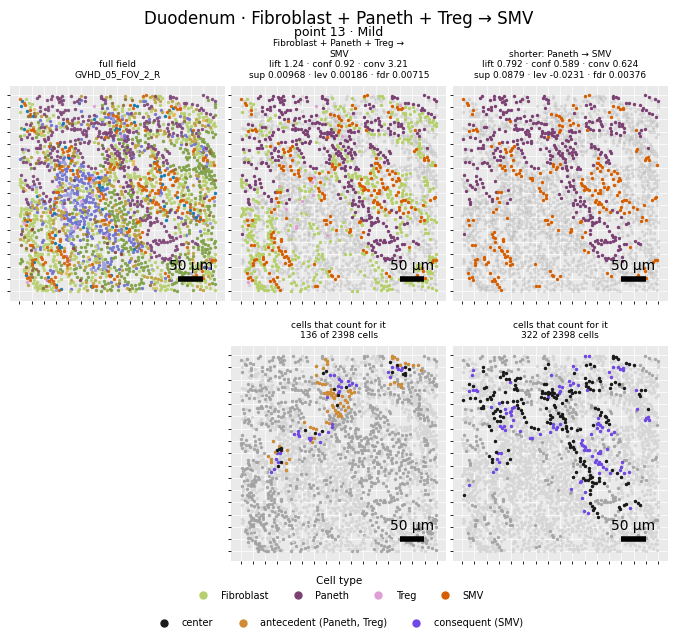

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\opposite_complex-antecedents_attracts_14_fovs.pdf


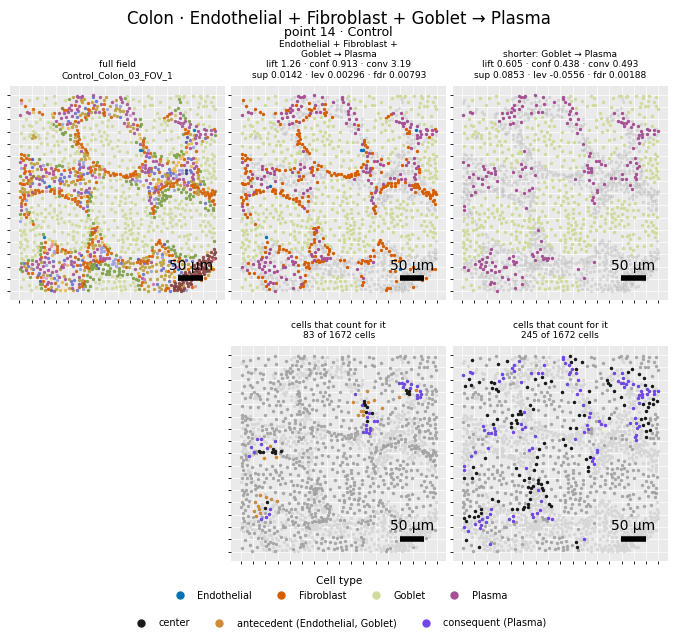

In [20]:
for index in picks.index:
    cc.show_rule(picks, index, picks, prepared, cells, metadata, ci.Config(), PREFIX)